In [68]:
import pandas as pd                                                                   # pandas
from sklearn.model_selection import train_test_split                                  # train test split
from sklearn.compose import ColumnTransformer                                         # column transformer
from sklearn.preprocessing import OneHotEncoder                                       # one-hot encode
from sklearn.tree import DecisionTreeClassifier                                       # decision tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score) # metrics
from sklearn.metrics import classification_report                                     # classification report
from sklearn.metrics import ConfusionMatrixDisplay                                    # error matrix
import matplotlib.pyplot as plt                                                       # matplotlib
from sklearn.tree import plot_tree                                                    # plot decision tree

In [69]:
df = pd.read_csv("dataset/ObesityDataSet_raw_and_data_sinthetic.csv")

In [70]:
# Let's check for missing values in the dataset
print(f"Missing values in the dataset: {df.isnull().sum().sum()}")

print("\n")

# Let's check for duplicate rows in the dataset
print(f"Duplicate rows in the dataset: {df.duplicated().sum()}")

# Let's remove duplicate rows
if(df.duplicated().sum() > 0):
   df = df.drop_duplicates()

Missing values in the dataset: 0


Duplicate rows in the dataset: 24


In [71]:
x = df.drop("NObeyesdad", axis=1) # axis=1 == axis='columns'

y = df["NObeyesdad"]

In [72]:
# Let's check the distribution of the target

print(y.value_counts())
print(y.value_counts(normalize=True) * 100)

NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_II    290
Normal_Weight          282
Overweight_Level_I     276
Insufficient_Weight    267
Name: count, dtype: int64
NObeyesdad
Obesity_Type_I         16.818400
Obesity_Type_III       15.524677
Obesity_Type_II        14.230954
Overweight_Level_II    13.895544
Normal_Weight          13.512218
Overweight_Level_I     13.224724
Insufficient_Weight    12.793483
Name: proportion, dtype: float64


In [73]:
# Let's separate the features into categorical and numerical

categorical_features = [
                "Gender", 
                "family_history_with_overweight", 
                "FAVC",
                "CAEC",
                "SMOKE",
                "SCC",
                "CALC",
                "MTRANS"
                    ]

numeric_features = [
                "Age",
                "Height",
                "Weight",
                "FCVC",
                "NCP",
                "CH2O",
                "FAF",
                "TUE"
                    ]

In [ ]:

# Let's split the dataset into training and testing

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1, stratify=y) 

In [75]:
# Let's decode categorical features using one-hot-encode and keep numerical features as they are

preprocessor = ColumnTransformer(transformers=[
    ("numerical", "passthrough", numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

x_train_processed = preprocessor.fit_transform(x_train)
x_test_processed  = preprocessor.transform(x_test)

In [76]:
# Let's create the decision tree

tree = DecisionTreeClassifier(random_state=1)

In [77]:
tree.fit(x_train_processed, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

In [78]:
pred_tree = tree.predict(x_test_processed)

In [79]:
print("======== Decision Tree ========")
print("Real values:")
print(y_test.head(10).to_list())

print("Decision Tree predictions:")
print(pred_tree[:10].tolist())

======== Decision Tree ========
Real values:
['Normal_Weight', 'Obesity_Type_I', 'Obesity_Type_III', 'Normal_Weight', 'Insufficient_Weight', 'Overweight_Level_II', 'Obesity_Type_III', 'Obesity_Type_III', 'Overweight_Level_I', 'Overweight_Level_II']
Decision Tree predictions:
['Normal_Weight', 'Obesity_Type_I', 'Obesity_Type_III', 'Normal_Weight', 'Insufficient_Weight', 'Overweight_Level_II', 'Obesity_Type_III', 'Obesity_Type_III', 'Overweight_Level_I', 'Overweight_Level_I']


In [80]:
# Accuracy  = number of correct predictions / total number of predictions

# Precision = Quando a arvore preve uma determinada classe, com que frequencia ela acerta, das vezes que previu obseidade, quantas vezes acertou

# Recall    = De todos os indivíduos que realmente pertencem a uma classe, quantos a árvore conseguiu identificar?
# de 20 indivíduos que realmente eram Normal_Weight, quantos foram classificados corretamente como Normal_Weight?

# F1-score = Combina Precision e Recall em uma única métrica, usando a média harmônica. É útil para avaliar o equilíbrio entre as duas.

metrics_df = pd.DataFrame([{
    "Accuracy": accuracy_score  (y_test, pred_tree),
    "Precision": precision_score(y_test, pred_tree, average="macro", zero_division=0),
    "Recall": recall_score      (y_test, pred_tree, average="macro", zero_division=0),
    "F1-score": f1_score        (y_test, pred_tree, average="macro", zero_division=0)
}], index=["Decision Tree"])

metrics_df.round(3)

,Accuracy,Precision,Recall,F1-score
Decision Tree,0.938,0.936,0.936,0.936


In [81]:
# Let's see the classification report for the decision tree

print("======== Decision Tree ========")
print(classification_report(y_test, pred_tree, zero_division=0))

======== Decision Tree ========
                     precision    recall  f1-score   support

Insufficient_Weight       0.94      0.96      0.95        53
      Normal_Weight       0.82      0.89      0.86        57
     Obesity_Type_I       0.98      0.93      0.96        70
    Obesity_Type_II       0.97      0.98      0.98        60
   Obesity_Type_III       1.00      1.00      1.00        65
 Overweight_Level_I       0.88      0.84      0.86        55
Overweight_Level_II       0.95      0.95      0.95        58

           accuracy                           0.94       418
          macro avg       0.94      0.94      0.94       418
       weighted avg       0.94      0.94      0.94       418



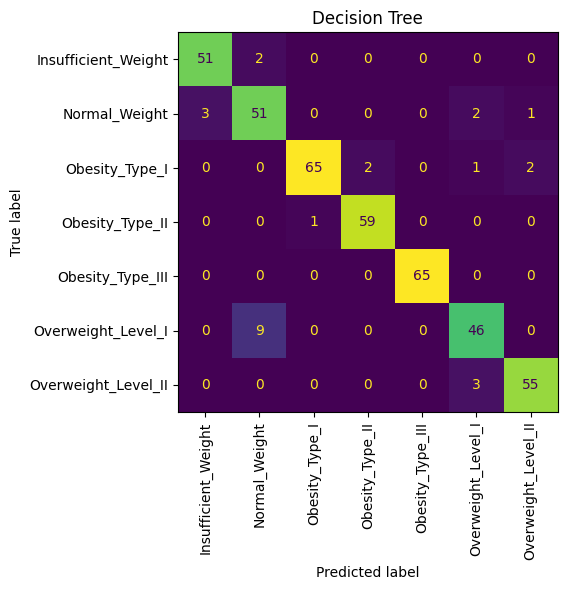

In [82]:

# Let's see the error matrix

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(y_test, pred_tree, xticks_rotation=90, ax=ax, colorbar=False)

ax.set_title("Decision Tree")
plt.tight_layout()
plt.show()


In [83]:

# Let's analyze feature importance in the Decision Tree

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({"Feature": feature_names, "Importance": tree.feature_importances_})

importance_df = importance_df.sort_values(by="Importance", ascending=False)

print(importance_df.to_string(index=False))


                                        Feature  Importance
                              numerical__Weight    0.429029
                              numerical__Height    0.249499
                     categorical__Gender_Female    0.157570
                                 numerical__Age    0.044551
                           categorical__CALC_no    0.028671
                          categorical__FAVC_yes    0.023412
                                numerical__FCVC    0.020084
                    categorical__CAEC_Sometimes    0.008775
                                numerical__CH2O    0.008469
                                 numerical__TUE    0.007104
                                 numerical__FAF    0.005258
                   categorical__CAEC_Frequently    0.004302
                       categorical__CAEC_Always    0.003325
                                 numerical__NCP    0.002728
                   categorical__CALC_Frequently    0.001868
                           categorical__

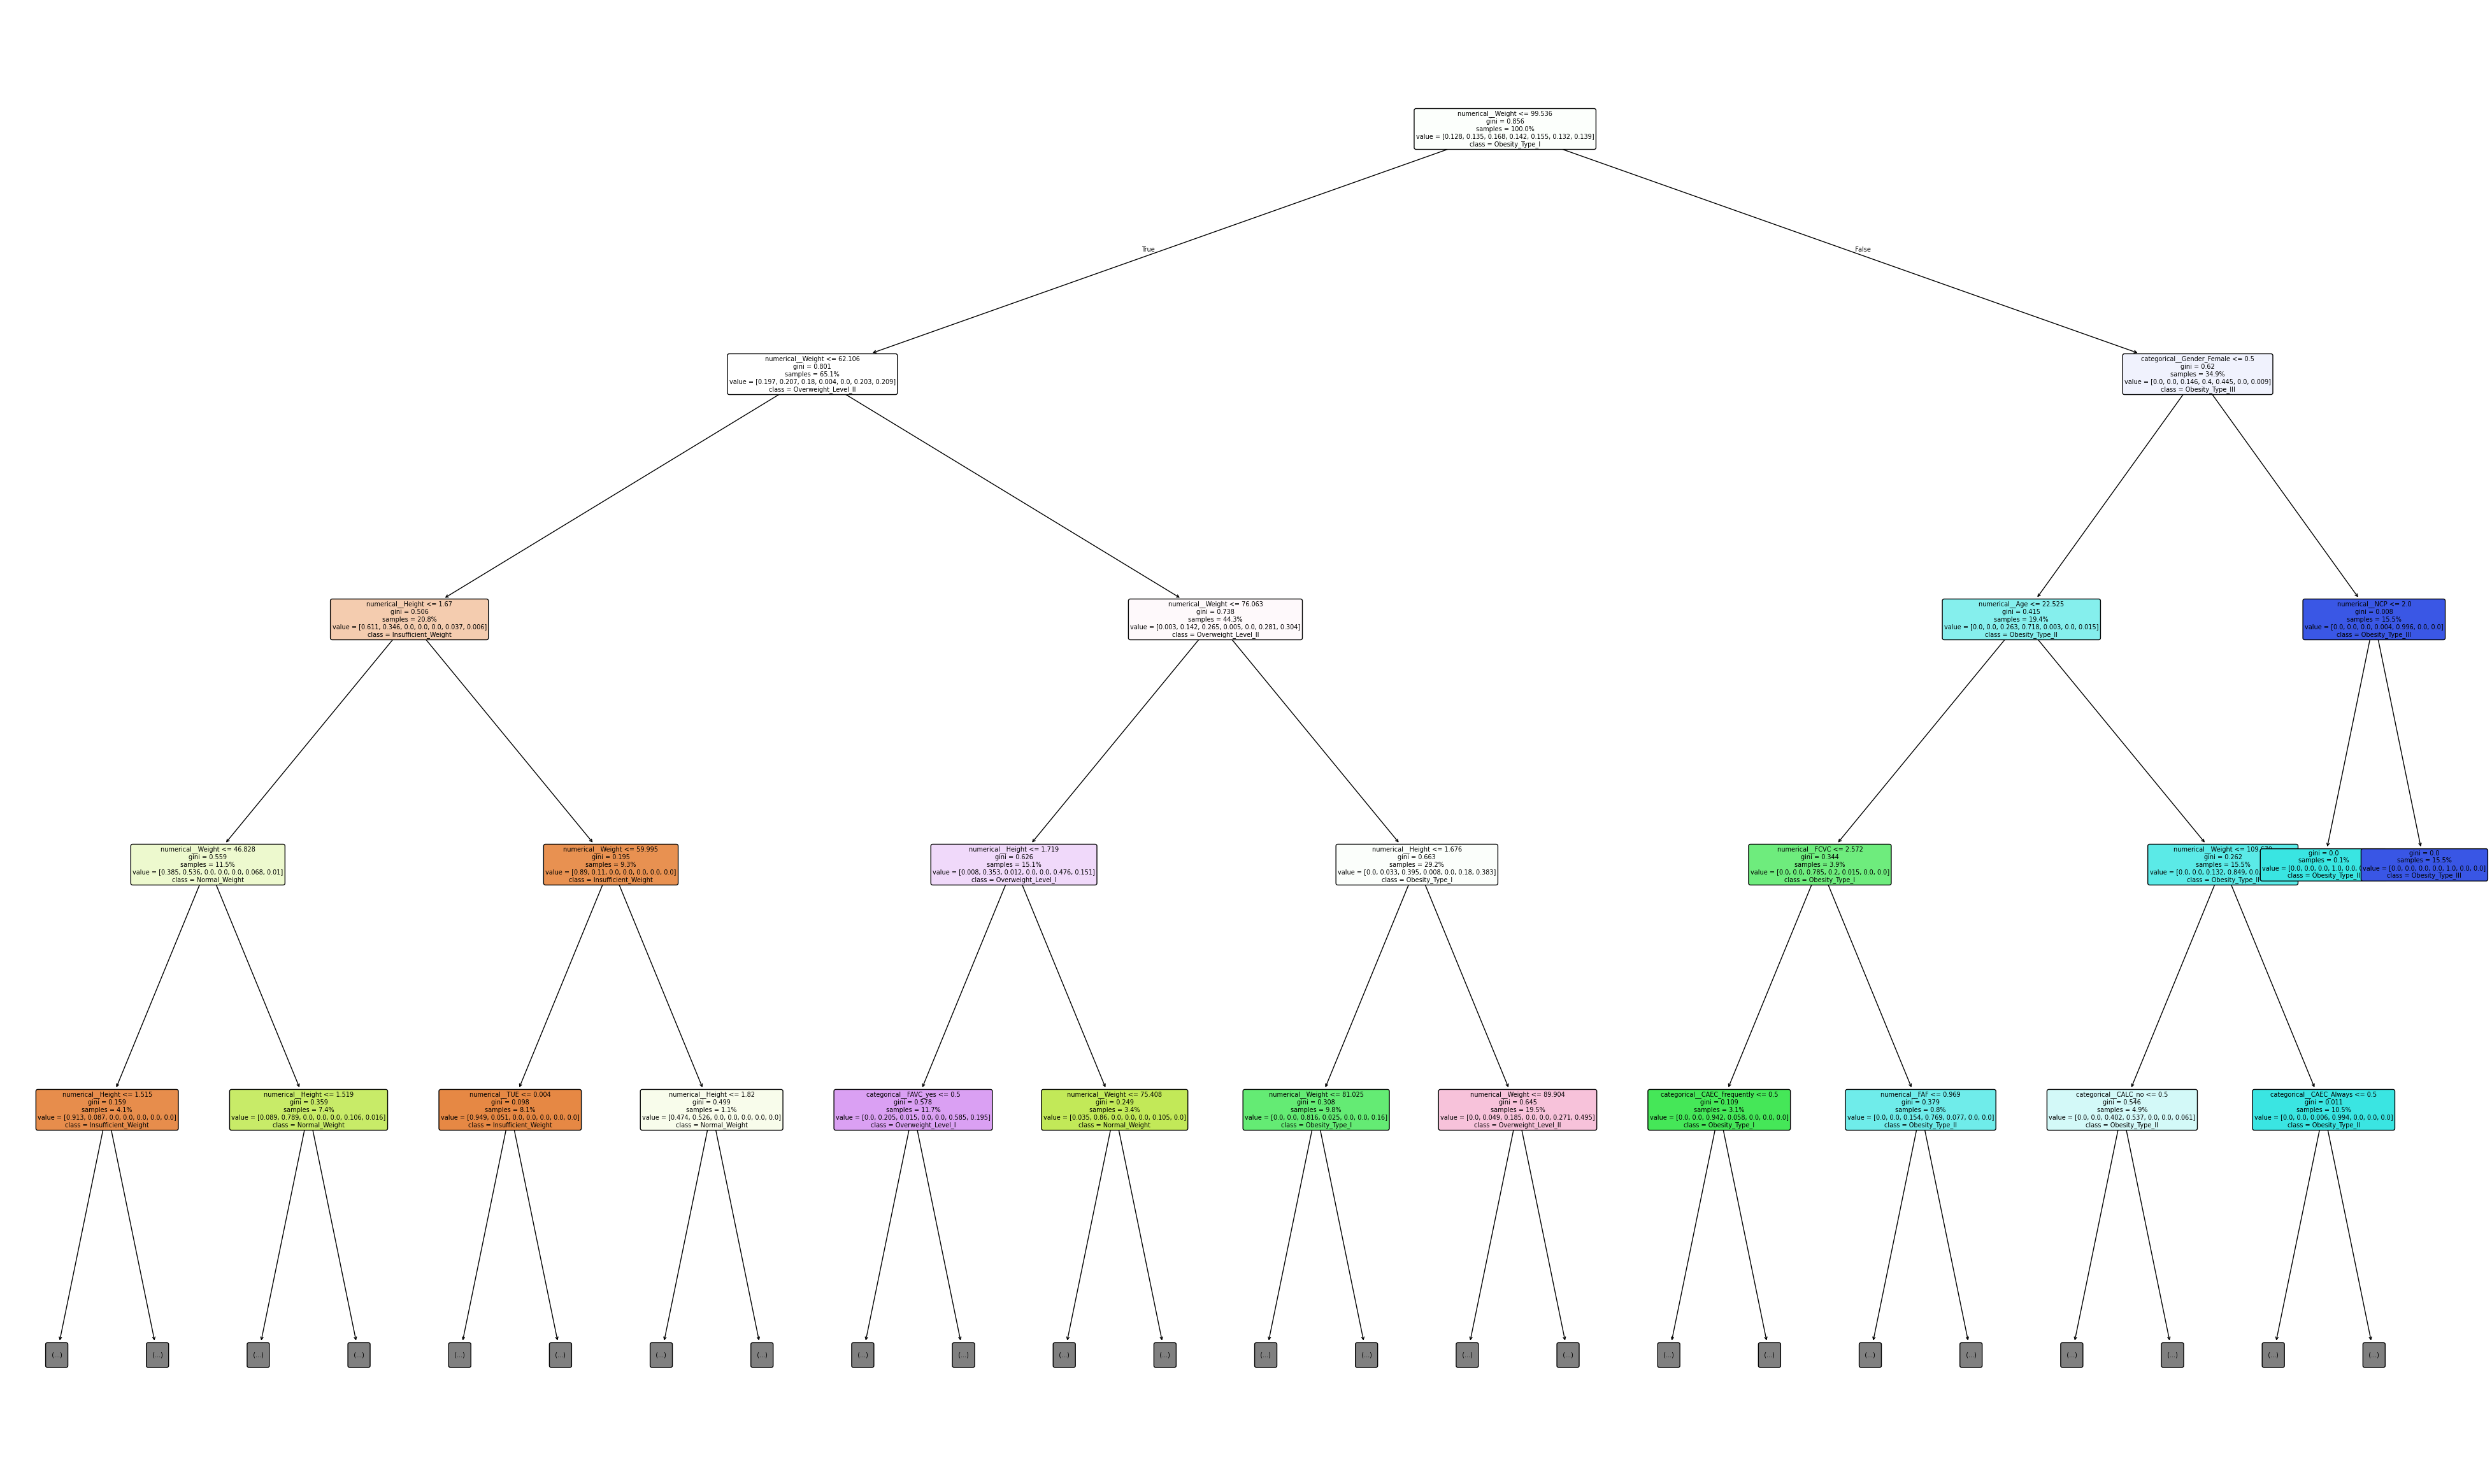

In [84]:
# Let's plot the decision tree

plt.figure(figsize=(50, 30))

plot_tree(
    tree,
    feature_names=preprocessor.get_feature_names_out(),
    class_names=tree.classes_,
    filled=True,
    rounded=True,
    max_depth=4,
    fontsize=7,
    proportion=True,
)

plt.show()